# resnet5m: a ResNet under 5M parameters for CIFAR-10

Everything here is read from the run folders produced by the CLI (`runs/<name>/`: `summary.json`, `metrics.csv`, `val_eval.json`), so the notebook needs no GPU and no checkpoints. Training commands are in the README.

## 1. Setup

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))

from cifar_resnet.config import load_config
from cifar_resnet.data import CLASSES, load_split
from cifar_resnet.models import build_model, count_parameters
from cifar_resnet.params import layer_table

FINAL_CONFIG = 'configs/student_v5.yaml'
FINAL_RUN = 'student_v5'
FINAL_FULL_RUN = 'student_v5_full'
KAGGLE_PUBLIC = {
    'wide3': 0.875,
    'student_full': 0.887,
    'student_long_full': 0.896,
    'student_v5_full': 0.899,
}

def read_json(path):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else None

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 2. Data

train (50000, 32, 32, 3) | test (2000, 32, 32, 3)
airplane      5000
automobile    5000
bird          5000
cat           5000
deer          5000
dog           5000
frog          5000
horse         5000
ship          5000
truck         5000
Name: count, dtype: int64


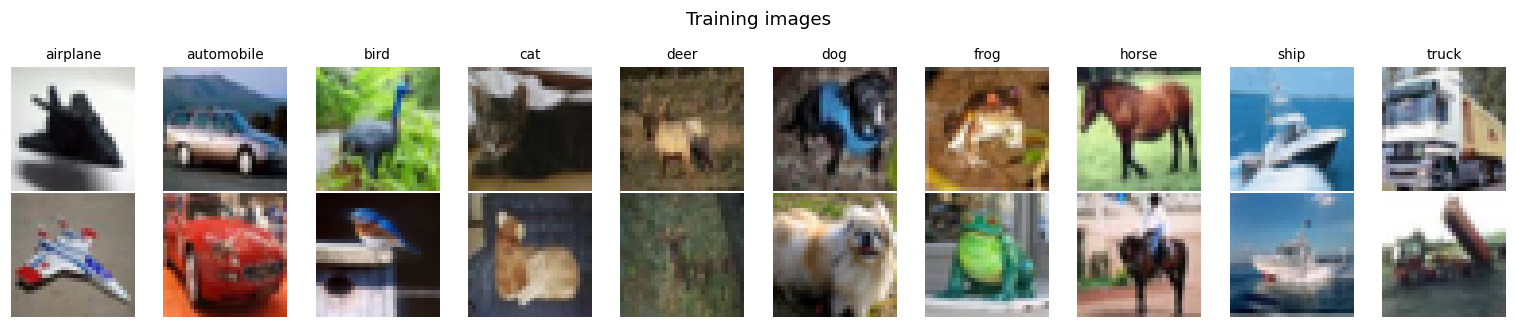

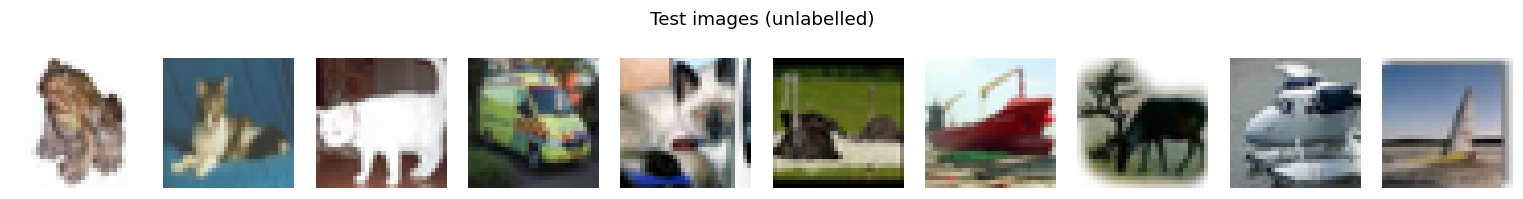

In [2]:
train_split = load_split('data', 'train', '.cache/data')
test_split = load_split('data', 'test', '.cache/data')
print('train', train_split.images.shape, '| test', test_split.images.shape)
print(pd.Series(train_split.labels).map(dict(enumerate(CLASSES))).value_counts().sort_index())

fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for c, col in enumerate(axes.T):
    idx = np.flatnonzero(train_split.labels == c)[:2]
    for ax, i in zip(col, idx):
        ax.imshow(train_split.images[i]); ax.axis('off')
    col[0].set_title(CLASSES[c], fontsize=9)
plt.suptitle('Training images'); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for ax, img in zip(axes, test_split.images[:10]):
    ax.imshow(img); ax.axis('off')
plt.suptitle('Test images (unlabelled)'); plt.tight_layout(); plt.show()

## 3. Model and parameter count

In [3]:
cfg = load_config(FINAL_CONFIG)
model = build_model(cfg.model)
print(model)
print(layer_table(model))
N_PARAMS = count_parameters(model)
assert N_PARAMS <= 5_000_000
print(f'Trainable parameters: {N_PARAMS:,}  (budget 5,000,000)')

ResNet(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (stages): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (se): Identity()
        (shortcut): Identity()
      )
      (1): BasicBlock(
        (conv1): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(96, 96, kernel

## 4. All runs

In [4]:
rows = [json.loads(p.read_text()) for p in sorted(Path('runs').glob('*/summary.json'))]
runs = pd.DataFrame(rows).set_index('run_name')
runs['kaggle_public'] = pd.Series(KAGGLE_PUBLIC)
cols = ['params', 'epochs', 'train_images', 'best_val_acc', 'best_val_acc_tta', 'kaggle_public', 'train_time_min']
runs = runs[[c for c in cols if c in runs]]
runs.sort_values('best_val_acc', ascending=False)

,params,epochs,train_images,best_val_acc,best_val_acc_tta,kaggle_public,train_time_min
run_name,,,,,,,
teacher_s3,36690090,400,45000,0.9774,0.9754,NaN,196.0
teacher_s4,36690090,400,45000,0.9768,0.9772,NaN,195.1
student_v5,4902506,1600,45000,0.9746,0.9748,NaN,0.0
teacher_s2,36690090,200,45000,0.9738,0.9740,NaN,100.7
teacher,36690090,200,45000,0.9728,0.9718,NaN,99.4
student_long,4902506,800,45000,0.9718,0.9720,NaN,232.2
teacher_s1,36690090,200,45000,0.9716,0.9726,NaN,100.8
student,4902506,300,45000,0.9714,0.9712,NaN,66.4
wide3,4337370,200,45000,0.9610,0.9644,0.875,26.8


## 5. Ablations (60 epochs each)

Same recipe, one change at a time, on the 45k/5k split. Short runs rank the choices; the winners were then trained for 200+ epochs.

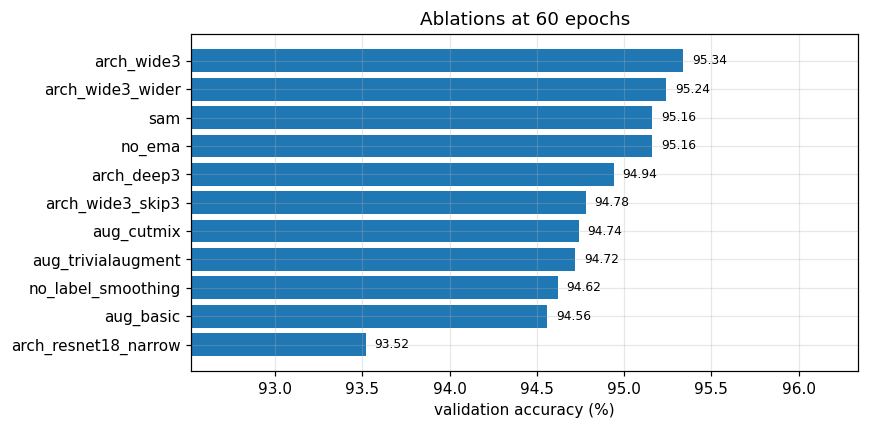

,params,best_val_acc,best_val_acc_tta,train_time_min
run_name,,,,
arch_resnet18_narrow,4815940,0.9352,0.9376,10.7
aug_basic,4337370,0.9456,0.9450,8.0
no_label_smoothing,4337370,0.9462,0.9514,8.9
aug_trivialaugment,4337370,0.9472,0.9534,8.8
aug_cutmix,4337370,0.9474,0.9482,9.0
arch_wide3_skip3,4849370,0.9478,0.9494,8.9
arch_deep3,4327754,0.9494,0.9520,9.8
no_ema,4337370,0.9516,0.9520,7.7
sam,4337370,0.9516,0.9520,12.6


In [5]:
abl = runs[runs.index.str.startswith('abl_')].copy()
abl.index = abl.index.str.replace('abl_', '')
abl = abl.sort_values('best_val_acc')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(abl.index, abl.best_val_acc * 100)
for y, v in enumerate(abl.best_val_acc * 100):
    ax.text(v + 0.05, y, f'{v:.2f}', va='center', fontsize=8)
ax.set(xlim=(abl.best_val_acc.min() * 100 - 1, abl.best_val_acc.max() * 100 + 1),
       xlabel='validation accuracy (%)', title='Ablations at 60 epochs')
plt.tight_layout(); plt.show()
abl[['params', 'best_val_acc', 'best_val_acc_tta', 'train_time_min']]

## 6. Training curves

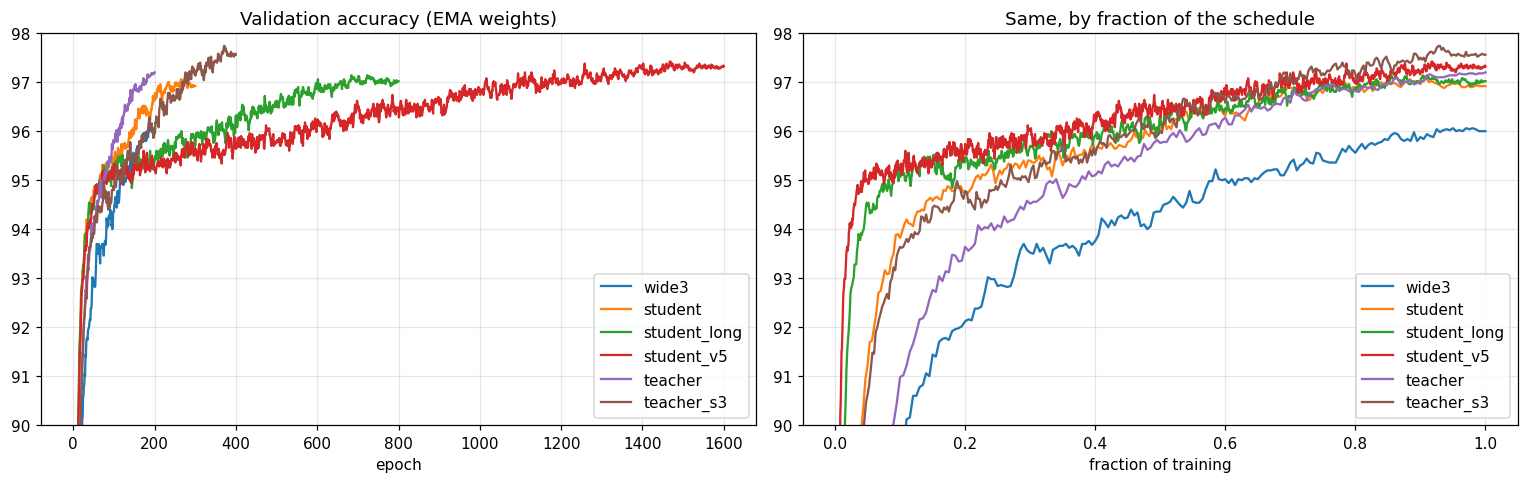

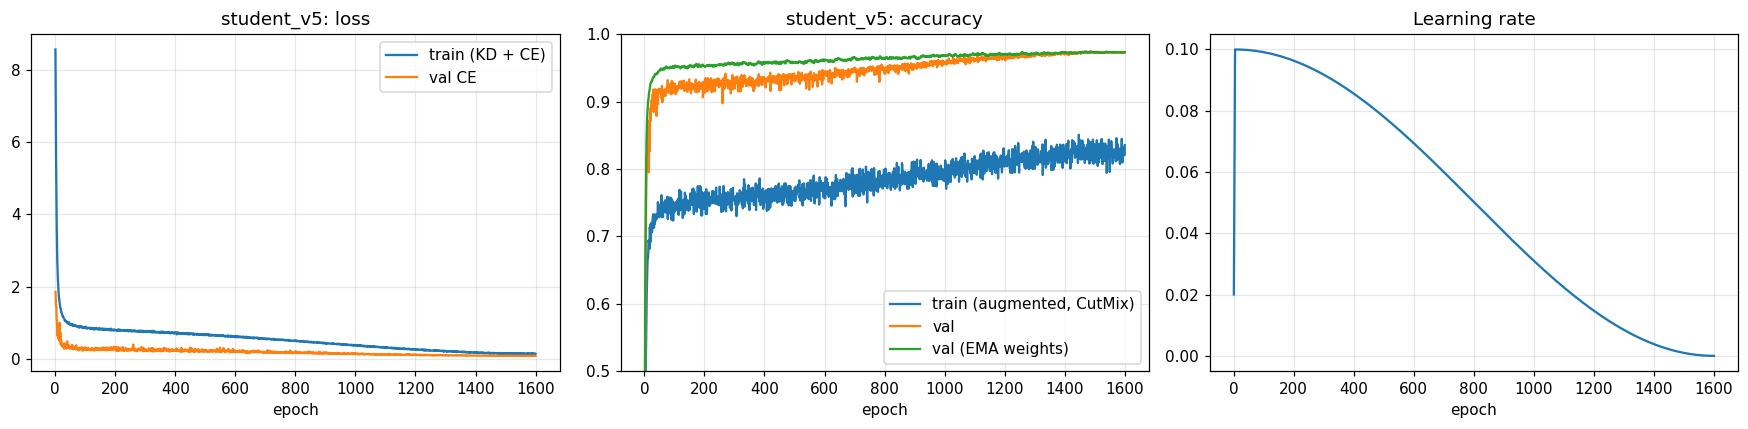

In [6]:
CURVES = ['wide3', 'student', 'student_long', 'student_v5', 'teacher', 'teacher_s3']
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name in CURVES:
    path = Path('runs') / name / 'metrics.csv'
    if not path.exists():
        continue
    m = pd.read_csv(path)
    acc = m.ema_val_acc.where(m.ema_val_acc.notna(), m.val_acc) if 'ema_val_acc' in m else m.val_acc
    ax[0].plot(m.epoch, acc * 100, label=name)
    ax[1].plot(m.epoch / m.epoch.max(), acc * 100, label=name)
ax[0].set(title='Validation accuracy (EMA weights)', xlabel='epoch', ylim=(90, 98))
ax[1].set(title='Same, by fraction of the schedule', xlabel='fraction of training', ylim=(90, 98))
for a in ax:
    a.legend()
plt.tight_layout(); plt.show()

m = pd.read_csv(Path('runs') / FINAL_RUN / 'metrics.csv')
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(m.epoch, m.train_loss, label='train (KD + CE)'); ax[0].plot(m.epoch, m.val_loss, label='val CE')
ax[0].set(title=f'{FINAL_RUN}: loss', xlabel='epoch'); ax[0].legend()
ax[1].plot(m.epoch, m.train_acc, label='train (augmented, CutMix)')
ax[1].plot(m.epoch, m.val_acc, label='val')
ax[1].plot(m.epoch, m.ema_val_acc, label='val (EMA weights)')
ax[1].set(title=f'{FINAL_RUN}: accuracy', xlabel='epoch', ylim=(0.5, 1)); ax[1].legend()
ax[2].plot(m.epoch, m.lr); ax[2].set(title='Learning rate', xlabel='epoch')
plt.tight_layout(); plt.show()

## 7. Teachers, distillation and schedule length

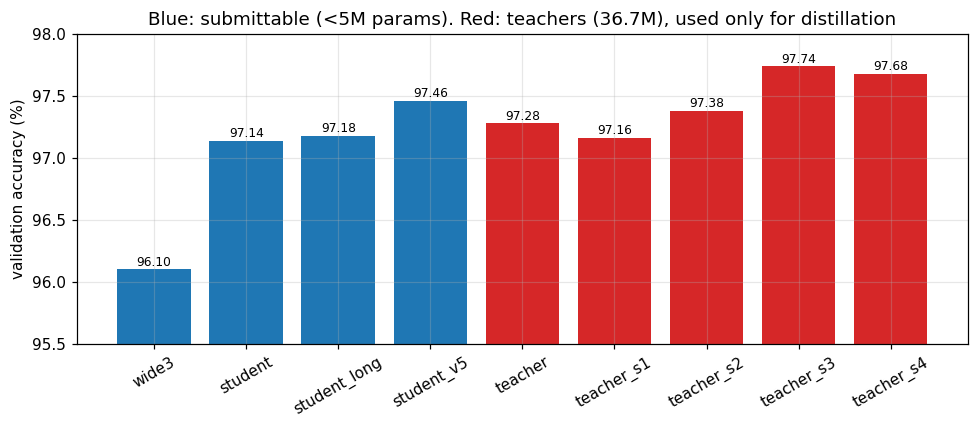

,params,epochs,best_val_acc,best_val_acc_tta
run_name,,,,
wide3,4337370,200,0.9610,0.9644
student,4902506,300,0.9714,0.9712
student_long,4902506,800,0.9718,0.9720
student_v5,4902506,1600,0.9746,0.9748
teacher,36690090,200,0.9728,0.9718
teacher_s1,36690090,200,0.9716,0.9726
teacher_s2,36690090,200,0.9738,0.9740
teacher_s3,36690090,400,0.9774,0.9754
teacher_s4,36690090,400,0.9768,0.9772


In [7]:
ladder = ['wide3', 'student', 'student_long', 'student_v5', 'teacher', 'teacher_s1', 'teacher_s2', 'teacher_s3', 'teacher_s4']
ladder = [r for r in ladder if r in runs.index]
sub = runs.loc[ladder, ['params', 'epochs', 'best_val_acc', 'best_val_acc_tta']]
fig, ax = plt.subplots(figsize=(9, 4))
colors = ['tab:red' if p > 5_000_000 else 'tab:blue' for p in sub.params]
ax.bar(sub.index, sub.best_val_acc * 100, color=colors)
for x, v in enumerate(sub.best_val_acc * 100):
    ax.text(x, v + 0.03, f'{v:.2f}', ha='center', fontsize=8)
ax.set(ylim=(95.5, 98), ylabel='validation accuracy (%)',
       title='Blue: submittable (<5M params). Red: teachers (36.7M), used only for distillation')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
sub

## 8. Validation analysis of the final model

run student_long: {'none': 0.972, 'flip': 0.9724, 'shift': 0.9712} (5000 held-out images)


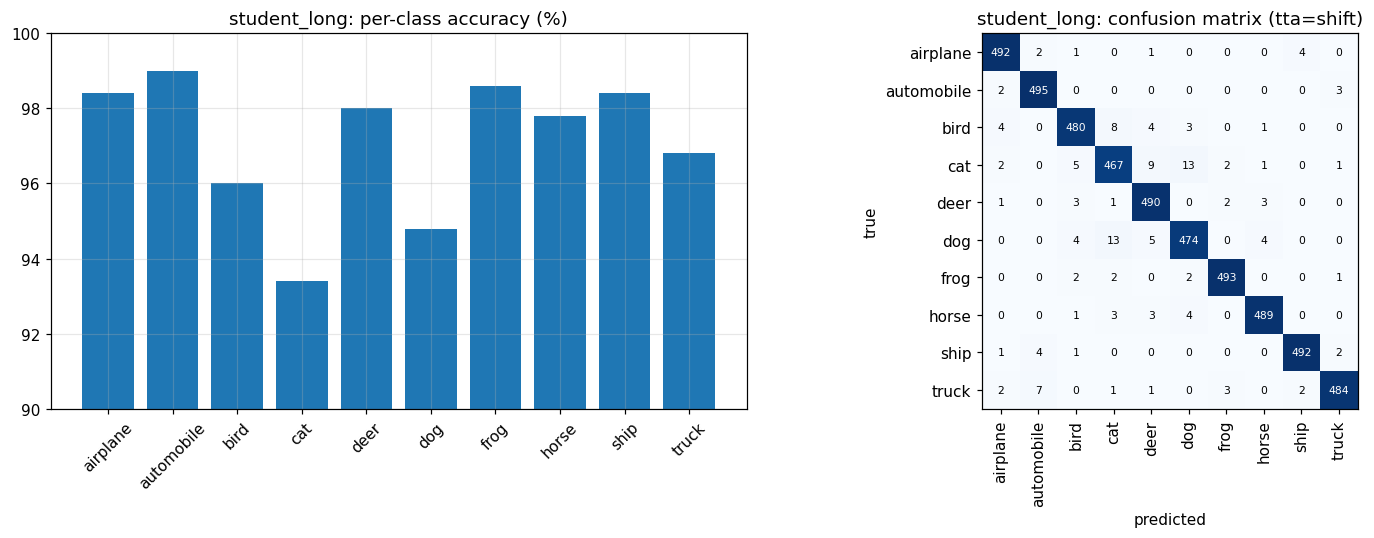

In [8]:
EVAL_RUN = next(r for r in [FINAL_RUN, 'student_long'] if (Path('runs') / r / 'val_eval.json').exists())
ev = read_json(Path('runs') / EVAL_RUN / 'val_eval.json')
print(f'run {EVAL_RUN}:', {k: round(v, 4) for k, v in ev['accuracy'].items()}, f"({ev['val_size']} held-out images)")
cm = np.array(ev['confusion'])
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(CLASSES, cm.diagonal() / cm.sum(1) * 100); ax[0].set(title=f'{EVAL_RUN}: per-class accuracy (%)', ylim=(90, 100))
ax[0].tick_params(axis='x', rotation=45)
ax[1].imshow(cm, cmap='Blues'); ax[1].set(title=f"{EVAL_RUN}: confusion matrix (tta={ev['confusion_tta']})", xlabel='predicted', ylabel='true')
ax[1].set_xticks(range(10), CLASSES, rotation=90); ax[1].set_yticks(range(10), CLASSES)
ax[1].grid(False)
for i in range(10):
    for j in range(10):
        ax[1].text(j, i, cm[i, j], ha='center', va='center', fontsize=7, color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout(); plt.show()

## 9. Final model and Kaggle submission

The submitted model is the same config retrained on all 50k images (`data.val_size=0`), predicted with flip TTA by `cifar-predict`.

In [9]:
sub = pd.read_csv(f'submissions/{FINAL_FULL_RUN}.csv')
sample = pd.read_csv('data/sample_submission.csv')
assert list(sub.columns) == ['id', 'label'] and (sub.id.values == sample.id.values).all()
print(sub.label.map(dict(enumerate(CLASSES))).value_counts().sort_index())

final = runs.loc[FINAL_FULL_RUN]
val = runs.loc[FINAL_RUN]
print('=' * 64)
print(f'Final model            : {FINAL_FULL_RUN} ({FINAL_CONFIG}, {int(final.epochs)} epochs, {int(final.train_images)} images)')
print(f'Trainable parameters   : {int(final.params):,} (limit 5,000,000)')
print(f'Validation accuracy    : {val.best_val_acc:.4f} plain, {val.best_val_acc_tta:.4f} with flip TTA (5k held-out, run {FINAL_RUN})')
print(f'Kaggle public accuracy : {KAGGLE_PUBLIC.get(FINAL_FULL_RUN)}')
print('=' * 64)

label
airplane      173
automobile    216
bird          206
cat           203
deer          196
dog           216
frog          184
horse         202
ship          203
truck         201
Name: count, dtype: int64
Final model            : student_v5_full (configs/student_v5.yaml, 1600 epochs, 50000 images)
Trainable parameters   : 4,902,506 (limit 5,000,000)
Validation accuracy    : 0.9746 plain, 0.9748 with flip TTA (5k held-out, run student_v5)
Kaggle public accuracy : 0.899
